# Annual top-1% overview

Who qualifies for the annual top 1%, and how concentrated is their funding?

**Scope:** The shared legal-form cohort in 2020-2025. Selection uses recipient-year amounts; summary tables contain one row per recipient code that qualifies at least once. Qualifying-year and all-year totals are kept separate.

This notebook identifies the annual top 1% within the shared legal-form cohort and summarizes recipients who qualify at least once. Recipient codes define identity; the latest name is a display label.

The [Methodology](../METHODOLOGY.md) documents definitions and correction policies. The [Project overview](../README.md) describes the notebook sequence and dataset rebuild process.

## Data sources and shared analysis functions

Cleaned funding records and shared analysis and chart functions provide the notebook's inputs.

In [ ]:
from pathlib import Path
import sys

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# Locate the checkout from the project folder or a notebook subfolder.
PROJECT_ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / "src" / "analysis_helpers.py").is_file()
     and (p / "config" / "sources.yaml").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open this notebook from within the project folder.")
SRC_DIR = PROJECT_ROOT / "src"

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from chart_style import apply_chart_style, colors_from_style, growth_cmap_from_style, load_chart_style

chart_style = load_chart_style(PROJECT_ROOT)
apply_chart_style(chart_style)
CHART_COLORS = colors_from_style(chart_style)
GROWTH_CMAP = growth_cmap_from_style(chart_style)
INTERIM_DIR = PROJECT_ROOT / "data" / "interim"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
from analysis_helpers import (
    latest_recipient_names,
    build_top_1_presence,
    build_top_1_streaks,
    load_vmi_support_by_recipient,
    prepare_top_1_dataset,
)

vmi = load_vmi_support_by_recipient(PROJECT_ROOT)

vmi.head()




,tax_year,recipient_municipality,recipient_code,recipient_name,legal_form,requests,calculated_pmd_eur,legal_form_clean
0,2025,Kauno m. sav.,191678556,Socialinių inovacijų fondas,Labdaros ir paramos fondas,7,604.80,Labdaros ir paramos fondas
1,2025,Plungės r. sav.,170075590,"Sporto klubas ""Makabi""",Asociacija,4,192.18,Asociacija
2,2025,Kauno m. sav.,193158860,Moters užimtumo informacijos centras,Asociacija,4,316.10,Asociacija
3,2025,Vilniaus m. sav.,124467262,"Paramos fondas ""Švietimo ir tyrimų institutas""",Labdaros ir paramos fondas,19,985.02,Labdaros ir paramos fondas
4,2025,Jurbarko r. sav.,191250833,Skirsnemunės Šv. Jurgio parapija,Tradicinė religinė bendruomenė ar bendrija,9,788.37,Tradicinė religinė bendruomenė ar bendrija


## Cohort selection and annual thresholds

The exclusion report and year-specific thresholds document the population underlying the rankings. Each threshold is the 99th percentile of positive adjusted amounts in that year's cohort. Values equal to the threshold are included, so ties can produce more than exactly 1%.

In [2]:
from cohort import START_YEAR, END_YEAR, LEGAL_FORM_REFERENCE_YEAR, filter_recipient_cohort, show_cohort_report
cohort_data, cohort_yearly_report, excluded_legal_forms, legal_form_changes = filter_recipient_cohort(vmi)
show_cohort_report(cohort_yearly_report, excluded_legal_forms, legal_form_changes)

df_filtered, top_1_df, yearly_thresholds = prepare_top_1_dataset(
    vmi,
    filter_year=LEGAL_FORM_REFERENCE_YEAR,
    percentile=99,
)

print("Rows in filtered data:", f"{len(df_filtered):,}")
print(
    "Unique recipients in filtered data:",
    f"{df_filtered['recipient_code'].nunique():,}",
)
print("Top 1% recipient-year records:", f"{len(top_1_df):,}")
print(
    "Unique recipients appearing in the annual top 1%:",
    f"{top_1_df['recipient_code'].nunique():,}",
)

print("\nTop 1% amount threshold for each year:")
display(
    yearly_thresholds.to_frame().style.format(
        {"top_1_threshold": "{:,.2f} €"}
    )
)

Legal forms observed in 2025; analysis years 2020-2025.
Filtering applies to recipient-year legal forms, not survival of each recipient in 2025.
Yearly inclusion and exclusion totals (amounts sum known values):


,tax_year,all_recipients,all_rows,all_pmd_eur,included_recipients,included_rows,included_pmd_eur,excluded_recipients,excluded_rows,excluded_pmd_eur,excluded_pmd_share,missing_amount_rows
0,2020,23240,23240,"21,654,753.19",16748,16748,"17,253,053.18",6492,6492,"4,401,700.01",20.33%,0
1,2021,22798,22798,"27,843,175.86",16325,16325,"22,940,811.40",6473,6473,"4,902,364.46",17.61%,0
2,2022,22147,22147,"29,202,852.20",15744,15744,"24,254,670.09",6403,6403,"4,948,182.11",16.94%,0
3,2023,22555,22555,"33,985,135.12",16252,16252,"28,543,797.48",6303,6303,"5,441,337.64",16.01%,0
4,2024,14511,14511,"36,904,168.23",14503,14503,"36,895,489.41",8,8,"8,678.82",0.02%,0
5,2025,15483,15483,"40,124,624.74",15483,15483,"40,124,624.74",0,0,0.00,0.00%,0


Excluded legal forms; absence is not evidence of legal ineligibility:


,legal_form_clean,exclusion_reason,recipients,rows,pmd_eur
0,Bendrija,Not observed in reference year,4048,13548,"4,267,247.25"
1,Biudžetinė įstaiga,Not observed in reference year,2436,8977,"13,942,264.28"
2,Mažoji bendrija,Not observed in reference year,15,54,"16,006.40"
3,"Prekybos, pramonės ir amatų rūmai",Not observed in reference year,4,13,"6,139.28"
4,Regiono plėtros taryba,Not observed in reference year,1,3,353.56
5,Sodininkų bendrija,Not observed in reference year,803,2869,"1,330,995.52"
6,Uždaroji akcinė bendrovė,Not observed in reference year,26,87,"83,911.66"
7,Šeimyna,Not observed in reference year,45,128,"55,345.09"


Recipients with multiple recorded legal forms: 0
The full legal_form_changes table retains every affected recipient-year; preview:


,recipient_code,recipient_name,tax_year,legal_form_clean,included_in_cohort


A recipient can appear in both inclusion groups within a year if its source records have different forms.


Rows in filtered data: 95,055
Unique recipients in filtered data: 23,401
Top 1% recipient-year records: 949
Unique recipients appearing in the annual top 1%: 302

Top 1% amount threshold for each year:


,top_1_threshold
tax_year,
2020,"9,710.19 €"
2021,"11,869.55 €"
2022,"12,492.24 €"
2023,"15,044.70 €"
2024,"19,907.18 €"
2025,"22,111.75 €"


## Qualifying-year and all-year funding scopes

Each recipient appears once. Fields ending in `top1_years` include only years of qualification; `all_years` fields include all recorded cohort years for those same recipients. The former is part of the latter, so the totals must not be added. Recipients can have different numbers of qualifying years.

In [3]:
top_1_unique = (
    top_1_df.groupby("recipient_code")
      .agg(
          years_in_top1=("tax_year", lambda x: ", ".join(map(str, sorted(x.unique())))),
          municipality=("recipient_municipality", "first"),
          legal_form=("legal_form_clean", "first"),
          records_in_top_1=("recipient_code", "count"),
          requests_top1_years=("requests", "sum"),
          pmd_top1_years=("calculated_pmd_eur", "sum"),
          median_annual_pmd_top1_years=("calculated_pmd_eur", "median"),
          max_annual_pmd_top1_years=("calculated_pmd_eur", "max")
      )
      .reset_index()
      .sort_values("pmd_top1_years", ascending=False)
)

top_1_unique.insert(1, "recipient_name",
    top_1_unique["recipient_code"].map(latest_recipient_names(df_filtered)))

# Full-period observations for exactly the same recipient codes.
all_year_rows = df_filtered.loc[
    df_filtered["recipient_code"].isin(top_1_unique["recipient_code"])
]
all_year_totals = all_year_rows.groupby("recipient_code", as_index=False).agg(
    years_observed_all_years=("tax_year", lambda s: ", ".join(map(str, sorted(s.unique())))),
    requests_all_years=("requests", "sum"),
    pmd_all_years=("calculated_pmd_eur", "sum"),
)
top_1_unique = top_1_unique.merge(all_year_totals, on="recipient_code", validate="one_to_one")
top_1_unique["pmd_outside_top1_years"] = top_1_unique["pmd_all_years"] - top_1_unique["pmd_top1_years"]
top_1_unique["requests_outside_top1_years"] = top_1_unique["requests_all_years"] - top_1_unique["requests_top1_years"]
assert top_1_unique["recipient_code"].is_unique
assert top_1_unique["pmd_outside_top1_years"].ge(-0.01).all()
assert top_1_unique["requests_outside_top1_years"].ge(0).all()
assert np.isclose(top_1_unique["pmd_all_years"].sum(), all_year_rows["calculated_pmd_eur"].sum(), rtol=0, atol=0.01)

# Keep the paired totals together for comparison.
paired_columns = ["recipient_code", "recipient_name", "years_in_top1", "years_observed_all_years",
                  "pmd_top1_years", "pmd_all_years", "pmd_outside_top1_years",
                  "requests_top1_years", "requests_all_years", "requests_outside_top1_years"]
top_1_unique = top_1_unique[paired_columns + [c for c in top_1_unique.columns if c not in paired_columns]]
top_1_unique = top_1_unique.sort_values("pmd_top1_years", ascending=False)
display(top_1_unique.head(20))
display(top_1_unique[["pmd_top1_years", "pmd_all_years", "pmd_outside_top1_years",
                      "requests_top1_years", "requests_all_years", "requests_outside_top1_years"]]
        .sum().to_frame("All ever-top-1% recipients"))


,recipient_code,recipient_name,years_in_top1,years_observed_all_years,pmd_top1_years,pmd_all_years,pmd_outside_top1_years,requests_top1_years,requests_all_years,requests_outside_top1_years,municipality,legal_form,records_in_top_1,median_annual_pmd_top1_years,max_annual_pmd_top1_years
0,303420560,"VšĮ ""Mėlyna ir geltona""","2020, 2021, 2022, 2023, 2024, 2025","2020, 2021, 2022, 2023, 2024, 2025",12227860.88,12227860.88,0.0,161322,161322,0,Vilniaus m. sav.,Viešoji įstaiga,6,2258361.240,3068047.50
1,302721009,Rimanto Kaukėno paramos grupė,"2020, 2021, 2022, 2023, 2024, 2025","2020, 2021, 2022, 2023, 2024, 2025",4988828.38,4988828.38,0.0,85233,85233,0,Vilniaus m. sav.,Labdaros ir paramos fondas,6,693044.020,1471194.93
2,301753623,Tėvynės sąjunga-Lietuvos krikščionys demokratai,"2020, 2021, 2022, 2023, 2024, 2025","2020, 2021, 2022, 2023, 2024, 2025",4597681.10,4597681.10,0.0,86820,86820,0,Vilniaus m. sav.,Politinė partija,6,698324.490,1176651.17
3,302288579,"Paramos ir labdaros fondas ""Mamų unija""","2020, 2021, 2022, 2023, 2024, 2025","2020, 2021, 2022, 2023, 2024, 2025",4200156.71,4200156.71,0.0,79222,79222,0,Vilniaus r. sav.,Labdaros ir paramos fondas,6,668168.290,1003965.20
4,305017992,"VšĮ ""Savanoriai vaikams""","2020, 2021, 2022, 2023, 2024, 2025","2020, 2021, 2022, 2023, 2024, 2025",2951463.31,2951463.31,0.0,51544,51544,0,Vilniaus m. sav.,Viešoji įstaiga,6,353281.525,1016991.27
5,304405807,Laisvės TV,"2020, 2021, 2022, 2023, 2024, 2025","2020, 2021, 2022, 2023, 2024, 2025",2502821.57,2502821.57,0.0,40194,40194,0,Vilniaus m. sav.,Viešoji įstaiga,6,415528.730,497917.54
6,190740859,Maltos ordino pagalbos tarnyba,"2020, 2021, 2022, 2023, 2024, 2025","2020, 2021, 2022, 2023, 2024, 2025",2488247.28,2488247.28,0.0,42404,42404,0,Vilniaus m. sav.,Asociacija,6,374462.850,613820.81
7,301536790,"VšĮ ""PENKTA KOJA""","2020, 2021, 2022, 2023, 2024, 2025","2020, 2021, 2022, 2023, 2024, 2025",2340164.44,2340164.44,0.0,48424,48424,0,Kauno m. sav.,Viešoji įstaiga,6,367797.085,545210.16
8,305205154,Laisvės partija,"2020, 2021, 2022, 2023, 2024, 2025","2020, 2021, 2022, 2023, 2024, 2025",1491247.94,1491247.94,0.0,32964,32964,0,Vilniaus m. sav.,Politinė partija,6,258389.635,297681.43
9,303379747,"Paramos fondas ""Gerų darbų dirbtuvės""","2020, 2021, 2022, 2023, 2024, 2025","2020, 2021, 2022, 2023, 2024, 2025",1450201.35,1450201.35,0.0,28547,28547,0,Vilniaus m. sav.,Labdaros ir paramos fondas,6,198134.395,424862.40


,All ever-top-1% recipients
pmd_top1_years,85005433.07
pmd_all_years,89350760.68
pmd_outside_top1_years,4345327.61
requests_top1_years,1613338.00
requests_all_years,1686997.00
requests_outside_top1_years,73659.00


## How concentrated is funding during qualifying years?

The table and chart rank recipients using funding during their top-1% years. Top-10, top-25 and top-50 groups overlap and are not separate shares to add. The denominator is all funding during qualifying years, not all funding in the source dataset.

In [4]:
top_1_concentration = pd.DataFrame({
    "group": ["Top 10 recipients", "Top 25 recipients", "Top 50 recipients", "All top 1% recipients"],
    "pmd_top1_years": [
        top_1_unique.head(10)["pmd_top1_years"].sum(),
        top_1_unique.head(25)["pmd_top1_years"].sum(),
        top_1_unique.head(50)["pmd_top1_years"].sum(),
        top_1_unique["pmd_top1_years"].sum()
    ]
})

top_1_concentration["share_of_top_1_pmd"] = top_1_concentration["pmd_top1_years"] / top_1_unique["pmd_top1_years"].sum()
top_1_concentration


,group,pmd_top1_years,share_of_top_1_pmd
0,Top 10 recipients,39238672.96,0.461602
1,Top 25 recipients,54382688.94,0.639755
2,Top 50 recipients,66325793.40,0.780254
3,All top 1% recipients,85005433.07,1.000000


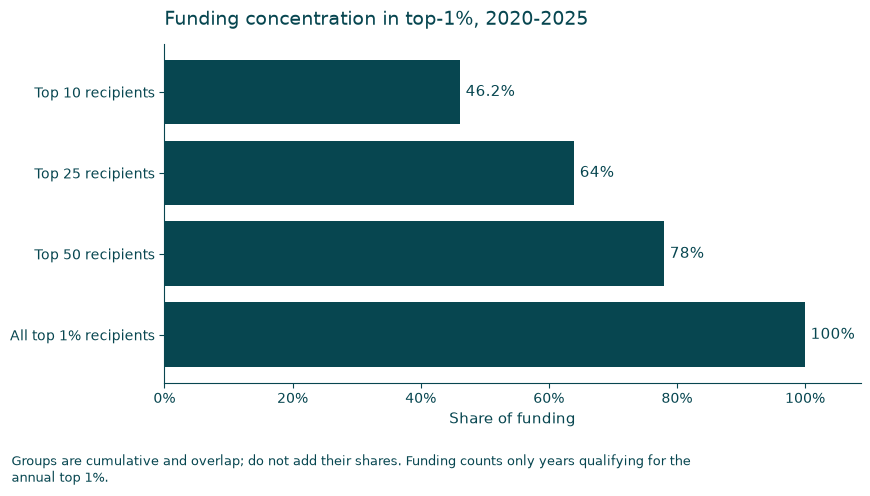

,group,pmd_top1_years,share_of_top_1_pmd
0,Top 10 recipients,39238672.96,0.461602
1,Top 25 recipients,54382688.94,0.639755
2,Top 50 recipients,66325793.40,0.780254
3,All top 1% recipients,85005433.07,1.000000


In [5]:
from chart_style import finish_chart, growth_boxplot, contrast_text

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(top_1_concentration["group"].iloc[::-1], top_1_concentration["share_of_top_1_pmd"].iloc[::-1], color=CHART_COLORS["primary"])
ax.bar_label(bars, labels=[f"{value:.1%}" for value in top_1_concentration["share_of_top_1_pmd"].iloc[::-1]], padding=4)
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:.0%}"))
ax.set(title="Funding concentration in top-1%, 2020-2025", xlabel="Share of funding", ylabel="")
finish_chart(plt.gcf(), 'Groups are cumulative and overlap; do not add their shares. Funding counts only years qualifying for the annual top 1%.')

display(top_1_concentration)


## Requests and funding during qualifying years

The ratio and correlations use qualifying-year totals. The 1,000-request split is an exploratory cutoff, not a discovered boundary. Different qualification durations and the arithmetic link between requests and funding limit interpretation; this is not a measure of supporters' wealth.

In [6]:
top_1_unique["average_amount_per_request_top1_years"] = top_1_unique["pmd_top1_years"] / top_1_unique["requests_top1_years"]

scatter_df = top_1_unique[(top_1_unique["requests_top1_years"] > 0) & (top_1_unique["pmd_top1_years"] > 0)].copy()
scatter_df["log_requests"] = np.log10(scatter_df["requests_top1_years"])
scatter_df["log_pmd"] = np.log10(scatter_df["pmd_top1_years"])

threshold_requests = 1000
low_group = scatter_df[scatter_df["requests_top1_years"] < threshold_requests]
high_group = scatter_df[scatter_df["requests_top1_years"] >= threshold_requests]

print("Overall correlation:", scatter_df[["log_requests", "log_pmd"]].corr().iloc[0, 1])
print("Correlation below 1,000 requests:", low_group[["log_requests", "log_pmd"]].corr().iloc[0, 1])
print("Correlation at or above 1,000 requests:", high_group[["log_requests", "log_pmd"]].corr().iloc[0, 1])


Overall correlation: 0.7957146394044935
Correlation below 1,000 requests: 0.11585097505542478
Correlation at or above 1,000 requests: 0.9466088164334263


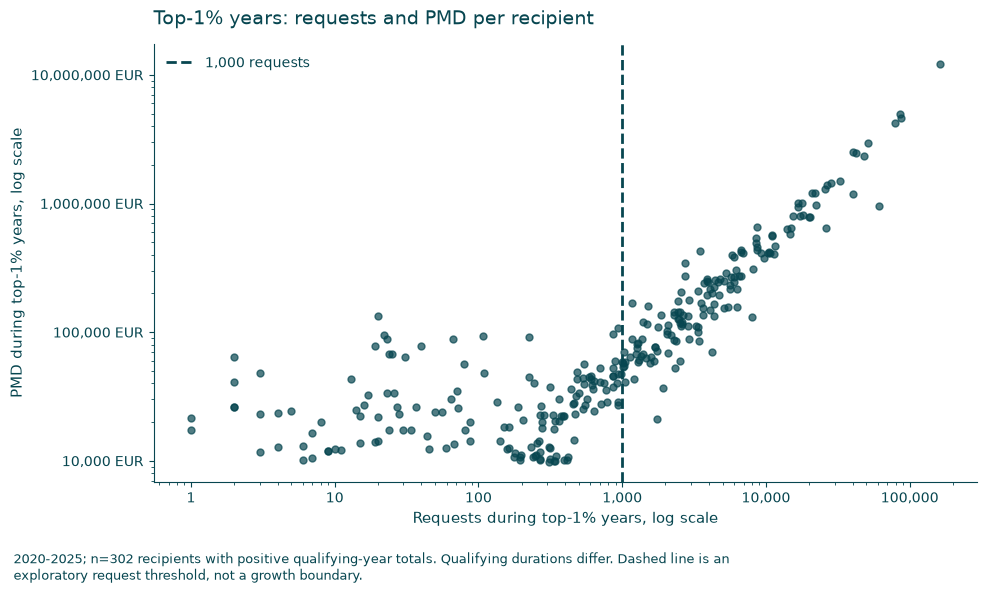

In [7]:
from chart_style import finish_chart, growth_boxplot, contrast_text

plt.figure(figsize=(10, 6))
plt.scatter(scatter_df["requests_top1_years"], scatter_df["pmd_top1_years"], alpha=0.7, color=CHART_COLORS["primary"])
plt.axvline(threshold_requests, color=CHART_COLORS["foreground"], linestyle="--", linewidth=2, label=f"{threshold_requests:,} requests")
plt.xscale("log")
plt.yscale("log")
plt.gca().xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"{x:,.0f}"))
plt.gca().yaxis.set_major_formatter(FuncFormatter(lambda y, pos: f"{y:,.0f} EUR"))
plt.title("Top-1% years: requests and PMD per recipient")
plt.xlabel("Requests during top-1% years, log scale")
plt.ylabel("PMD during top-1% years, log scale")
plt.legend()
plt.grid(False, which="both")

finish_chart(plt.gcf(), f"2020-2025; n={len(scatter_df):,} recipients with positive qualifying-year totals. Qualifying durations differ. Dashed line is an exploratory request threshold, not a growth boundary.")



## Reading the results together

This notebook describes the annual top-1% population across the period. The next notebook distinguishes occasional qualification from persistent membership.

[Previous notebook](03_legal_forms_analysis.ipynb) | [Next notebook](05_top_1_persistent_recipients.ipynb) | [Reading guide](../README.md#reading-order)